In [1]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from timesfm3 import TimesFM3Forecaster

device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch", device=device)

MODEL_LABEL = "TimesFM 3.0"
MAX_CONTEXT = pipeline.global_context
MAX_HORIZON = 1024
print(f"Loaded {MODEL_LABEL} on {device}")

Loaded TimesFM 3.0 on cuda


In [2]:
# Load data
import json

DATA_FILE = "tep_sp_spaced_6min_noisy.h5"


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


groups = {}
with h5py.File(DATA_FILE, "r") as f:
    time_h = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "dist", "sp"]:
        groups[key] = (f[key][()], read_names(f[key]))
    if "y" in f:   # true valve positions
        groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])
    config = json.loads(f.attrs["config"])
SAMPLE_MIN = config["record_every"] / 60   # sampling interval (min)

nominal = {int(k): v for k, v in config["setpoints"].items()}
CHANGED = sorted({k for k, _, _ in config["setpoint_schedule"]})   # set points changed in this run
t_test = config.get("t_test")                                    # start of the test changes (h)

sp = groups["sp"][0]
off = {k: np.abs(sp[:, k - 1] - nominal[k]) > 1e-9 for k in CHANGED}
sp_change = np.zeros(len(time_h), dtype=int)
for k in reversed(CHANGED):
    sp_change[off[k]] = k

data = {"time_h": time_h, "sp_change": sp_change}
COLUMNS, LABELS = {}, {}
for group, (values, labels) in groups.items():
    COLUMNS[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
    for col, v, label in zip(COLUMNS[group], values.T, labels):
        data[col] = v
        LABELS[col] = label

df = pd.DataFrame(data)
df.insert(0, "item_id", "tep")
df.insert(1, "timestamp", pd.date_range("2026-01-01", periods=len(df), freq=f"{config['record_every']}s"))

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
print(f"{len(df)} samples ({time_h[-1]:.0f} h), {len(TARGET_COLUMNS)} targets, covariate groups: "
      + ", ".join(f"{g} ({len(COLUMNS[g])})" for g in COLUMNS if g not in ["xmeas", "xmv"]))
print(f"changed set points: {CHANGED}, test part from {t_test} h")
df.head()

6798 samples (680 h), 53 targets, covariate groups: dist (12), sp (20), valve (12)
changed set points: [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20], test part from 580.6 h


,item_id,timestamp,time_h,sp_change,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,valve_3,valve_4,valve_5,valve_6,valve_7,valve_8,valve_9,valve_10,valve_11,valve_12
0,tep,2026-01-01 00:00:00,0.1,0,0.250570,3646.911201,4529.162678,9.361743,26.955182,42.374646,...,24.683121,61.476138,22.362808,40.095187,38.413928,46.439184,47.490184,40.948926,17.063033,50.0
1,tep,2026-01-01 00:06:00,0.2,0,0.251641,3685.782817,4532.305731,9.392197,27.192827,42.306830,...,24.669825,61.220980,22.282045,39.990620,38.834873,46.076364,47.465945,40.781658,19.495237,50.0
2,tep,2026-01-01 00:12:00,0.3,0,0.224798,3649.568095,4485.146695,9.372377,26.672050,42.430624,...,21.892922,61.453199,22.133312,40.754288,37.087577,47.823150,47.578868,40.150284,16.873578,50.0
3,tep,2026-01-01 00:18:00,0.4,0,0.218406,3639.328339,4472.573385,9.490855,26.897409,42.106486,...,21.619293,61.542878,22.350442,40.748417,34.570768,46.721658,47.682376,40.822785,17.567854,50.0
4,tep,2026-01-01 00:24:00,0.5,0,0.259690,3665.940633,4583.163603,9.290618,27.026282,42.238532,...,25.661680,61.170016,21.863833,42.083198,38.107019,48.403660,47.805239,40.148750,18.059470,50.0


In [3]:
# Pick a forecast window
events = []   # (start index, end index, set point, new value)
for k in CHANGED:
    on = off[k]
    for i in range(len(on)):
        if on[i] and (i == 0 or not on[i - 1]):
            start = i
        if on[i] and (i == len(on) - 1 or not on[i + 1]):
            events.append((start, i, k, sp[start, k - 1]))
events.sort()

for n, (s, e, k, v) in enumerate(events):
    part = "test " if t_test is not None and time_h[s] >= t_test else "train"
    print(f"{n:2d}  {part}  SP {k:2d}  samples {s:4d}-{e:4d}  ({time_h[s]:5.1f}-{time_h[e]:5.1f} h)  "
          f"{nominal[k]:.4g} -> {v:.4g} ({100 * (v - nominal[k]) / nominal[k]:+.1f}%)  {LABELS[f'sp_{k}']}")

EVENT_INDEX = 67
START = None
BUFFER = 20
HORIZON = 200
PLOT_LEAD_IN = 200

event_start, event_end, event_sp, event_value = events[EVENT_INDEX]
if START is None:
    SPLIT = max(event_start - BUFFER, 0)
    default_horizon = event_end - SPLIT + 100
else:
    SPLIT = START
    default_horizon = MAX_HORIZON
HORIZON = min(HORIZON or default_horizon, MAX_HORIZON, len(df) - SPLIT)
context_used = min(SPLIT, MAX_CONTEXT)

window_changes = [k for k in CHANGED if off[k][SPLIT:SPLIT + HORIZON].any()]
print(f"\nForecast from sample {SPLIT} ({time_h[SPLIT]:.1f} h), horizon {HORIZON} samples ({HORIZON * SAMPLE_MIN / 60:.1f} h)")
print(f"Context: {SPLIT} samples available, {context_used} used (model max {MAX_CONTEXT})")
print(f"Set points off nominal in the forecast window: {window_changes if window_changes else 'none'}")

 0  train  SP 14  samples   99- 148  ( 10.0- 14.9 h)  6.882 -> 7.282 (+5.8%)  Reactor feed D (mol%)
 1  train  SP 18  samples  201- 220  ( 20.2- 22.1 h)  120.4 -> 121.5 (+0.9%)  Reactor temperature (C)
 2  train  SP 19  samples  247- 296  ( 24.8- 29.7 h)  13.82 -> 12.42 (-10.1%)  Purge B (mol%)
 3  train  SP 17  samples  355- 394  ( 35.6- 39.5 h)  75 -> 75.88 (+1.2%)  Reactor level (%)
 4  train  SP  8  samples  437- 456  ( 43.8- 45.7 h)  50 -> 55.6 (+11.2%)  Stripper level (%)
 5  train  SP 13  samples  480- 529  ( 48.1- 53.0 h)  32.19 -> 33.39 (+3.7%)  Reactor feed A (mol%)
 6  train  SP 11  samples  589- 628  ( 59.0- 62.9 h)  22.95 -> 23.23 (+1.2%)  Stripper underflow (m3/h)
 7  train  SP 17  samples  675- 714  ( 67.6- 71.5 h)  75 -> 73.25 (-2.3%)  Reactor level (%)
 8  train  SP 14  samples  760- 809  ( 76.1- 81.0 h)  6.882 -> 6.602 (-4.1%)  Reactor feed D (mol%)
 9  train  SP 17  samples  867- 906  ( 86.8- 90.7 h)  75 -> 72.5 (-3.3%)  Reactor level (%)
10  train  SP 17  samples  9

In [4]:
# Covariates
USE_DIST = False                 # disturbance signals (12)
USE_SP = True                    # changed set points (11)
USE_VALVE = False                # true valve positions (12)
DROPPED = []
PAST_ONLY = []
COVARIATES_KNOWN_FUTURE = True

COVARIATE_COLUMNS = []
for group, use in [("dist", USE_DIST), ("sp", USE_SP), ("valve", USE_VALVE)]:
    if use and group in COLUMNS:
        COVARIATE_COLUMNS += [f"sp_{k}" for k in CHANGED] if group == "sp" else COLUMNS[group]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in DROPPED]

context_df = df.iloc[SPLIT - context_used:SPLIT]
truth_df = df.iloc[SPLIT:SPLIT + HORIZON]

window_df = pd.concat([context_df, truth_df])
constant = [c for c in COVARIATE_COLUMNS if window_df[c].nunique() == 1]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in constant]

FUTURE_COV = [c for c in COVARIATE_COLUMNS if COVARIATES_KNOWN_FUTURE and c not in PAST_ONLY]
PAST_ONLY_COV = [c for c in COVARIATE_COLUMNS if c not in FUTURE_COV]

print(f"targets ({len(TARGET_COLUMNS)}): {', '.join(TARGET_COLUMNS)}")
print(f"past + future covariates ({len(FUTURE_COV)}): {', '.join(FUTURE_COV) or '-'}")
print(f"past-only covariates ({len(PAST_ONLY_COV)}): {', '.join(PAST_ONLY_COV) or '-'}")
if constant:
    print(f"left out, constant over the window ({len(constant)}): {', '.join(constant)}")

targets (53): xmeas_1, xmeas_2, xmeas_3, xmeas_4, xmeas_5, xmeas_6, xmeas_7, xmeas_8, xmeas_9, xmeas_10, xmeas_11, xmeas_12, xmeas_13, xmeas_14, xmeas_15, xmeas_16, xmeas_17, xmeas_18, xmeas_19, xmeas_20, xmeas_21, xmeas_22, xmeas_23, xmeas_24, xmeas_25, xmeas_26, xmeas_27, xmeas_28, xmeas_29, xmeas_30, xmeas_31, xmeas_32, xmeas_33, xmeas_34, xmeas_35, xmeas_36, xmeas_37, xmeas_38, xmeas_39, xmeas_40, xmeas_41, xmv_1, xmv_2, xmv_3, xmv_4, xmv_5, xmv_6, xmv_7, xmv_8, xmv_9, xmv_10, xmv_11, xmv_12
past + future covariates (11): sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15, sp_17, sp_18, sp_19, sp_20
past-only covariates (0): -


In [5]:
# Run TimesFM 3.0
QUANTILES = [0.1, 0.5, 0.9]
VARIATES_PER_CALL = None

if VARIATES_PER_CALL is None:
    targets_per_call = len(TARGET_COLUMNS)
else:
    targets_per_call = VARIATES_PER_CALL - len(COVARIATE_COLUMNS)
    if targets_per_call < 1:
        raise ValueError(f"{len(COVARIATE_COLUMNS)} covariates leave no room for targets in {VARIATES_PER_CALL} series")

past_only_cov = None
if PAST_ONLY_COV:
    past_only_cov = context_df[PAST_ONLY_COV].to_numpy(dtype=np.float32).T                    # (covariates, context)
past_future_cov = None
if FUTURE_COV:
    past_future_cov = window_df[FUTURE_COV].to_numpy(dtype=np.float32).T                      # (covariates, context + horizon)

forecast, quantiles = [], []
for i in range(0, len(TARGET_COLUMNS), targets_per_call):
    chunk = TARGET_COLUMNS[i:i + targets_per_call]
    out = pipeline.predict(
        context_df[chunk].to_numpy(dtype=np.float32).T,                                       # (targets, context)
        horizon=HORIZON,
        past_only_covariates=past_only_cov,
        past_future_covariates=past_future_cov,
        return_quantiles=True,
    )
    forecast.append(out.forecast[:, :HORIZON])
    quantiles.append(out.quantiles[:, :HORIZON])
forecast = np.concatenate(forecast)     # (targets, horizon) median
quantiles = np.concatenate(quantiles)   # (targets, horizon, 9) deciles 0.1 .. 0.9

q_index = {q: pipeline.config.quantiles.index(q) for q in QUANTILES}
pred_df = pd.concat(
    [
        pd.DataFrame({
            "timestamp": truth_df["timestamp"].values,
            "time_h": truth_df["time_h"].values,
            "target_name": col,
            "predictions": forecast[v],
            **{str(q): quantiles[v, :, i] for q, i in q_index.items()},
        })
        for v, col in enumerate(TARGET_COLUMNS)
    ],
    ignore_index=True,
)
pred_df.head()

,timestamp,time_h,target_name,predictions,0.1,0.5,0.9
0,2026-01-25 11:24:00,587.5,xmeas_1,0.289439,0.251974,0.289439,0.323847
1,2026-01-25 11:30:00,587.6,xmeas_1,0.282433,0.242084,0.282433,0.320727
2,2026-01-25 11:36:00,587.7,xmeas_1,0.274281,0.233223,0.274281,0.314360
3,2026-01-25 11:42:00,587.8,xmeas_1,0.273346,0.231316,0.273346,0.314432
4,2026-01-25 11:48:00,587.9,xmeas_1,0.266933,0.224129,0.266933,0.308711


In [6]:
# Accuracy
normal_context = context_df[context_df["sp_change"] == 0]
in_fault = truth_df["sp_change"].to_numpy() != 0
last_value = context_df.iloc[-1]

rows = []
for col in TARGET_COLUMNS:
    pred = pred_df.loc[pred_df["target_name"] == col, "predictions"].to_numpy()
    actual = truth_df[col].to_numpy()
    scale = normal_context[col].std()
    if scale == 0:
        scale = np.nan
    err = pd.Series(np.abs(pred - actual) / scale)
    base_err = pd.Series(np.abs(last_value[col] - actual) / scale)
    rows.append({
        "variable": col,
        "description": LABELS[col],
        "MAE": np.abs(pred - actual).mean(),
        "scaled MAE (nominal)": err[~in_fault].mean(),
        "scaled MAE (off nominal)": err[in_fault].mean(),
        "scaled MAE (all)": err.mean(),
        "baseline (nominal)": base_err[~in_fault].mean(),
        "baseline (off nominal)": base_err[in_fault].mean(),
        "baseline (all)": base_err.mean(),
    })
accuracy = pd.DataFrame(rows).set_index("variable")

phases = ["nominal", "off nominal", "all"]
summary = pd.DataFrame({
    MODEL_LABEL: [accuracy[f"scaled MAE ({p})"].mean() for p in phases],
    "last-value baseline": [accuracy[f"baseline ({p})"].mean() for p in phases],
    "samples": [(~in_fault).sum(), in_fault.sum(), len(in_fault)],
}, index=phases)
print(f"Mean scaled MAE over {accuracy['scaled MAE (all)'].notna().sum()} scored targets")
print(summary.round(3).to_string())
beats = (accuracy["scaled MAE (all)"] < accuracy["baseline (all)"]).sum()
print(f"{MODEL_LABEL} beats the baseline on {beats} / {accuracy['scaled MAE (all)'].notna().sum()} targets")
accuracy.sort_values("scaled MAE (all)", ascending=False).round(4)

Mean scaled MAE over 52 scored targets
             TimesFM 3.0  last-value baseline  samples
nominal            0.571                1.043      112
off nominal        0.590                1.028       88
all                0.579                1.036      200
TimesFM 3.0 beats the baseline on 52 / 52 targets


,description,MAE,scaled MAE (nominal),scaled MAE (off nominal),scaled MAE (all),baseline (nominal),baseline (off nominal),baseline (all)
variable,,,,,,,,
xmeas_6,Reactor feed rate (kscmh),0.2224,0.8133,1.0472,0.9162,1.1744,1.8614,1.4767
xmeas_5,Recycle flow (kscmh),0.1814,0.7697,0.9326,0.8414,0.7936,1.4575,1.0857
xmeas_14,Separator underflow (m3/h),0.8606,0.8322,0.7595,0.8002,0.8495,0.8094,0.8318
xmeas_15,Stripper level (%),0.8401,0.7650,0.8362,0.7963,0.8351,0.8968,0.8623
xmv_8,Stripper product flow,1.9439,0.7647,0.8361,0.7961,0.8351,0.8968,0.8623
xmeas_17,Stripper underflow (m3/h),0.5174,0.8194,0.7623,0.7943,1.6255,1.4784,1.5607
xmv_11,Condenser CW flow,1.2386,0.8037,0.7529,0.7814,1.5391,1.3929,1.4748
xmv_10,Reactor CW flow,0.5998,0.7217,0.8506,0.7784,1.4936,1.4670,1.4819
xmeas_41,Product H (mol%),0.4564,0.7609,0.7703,0.7651,0.9977,0.7903,0.9064


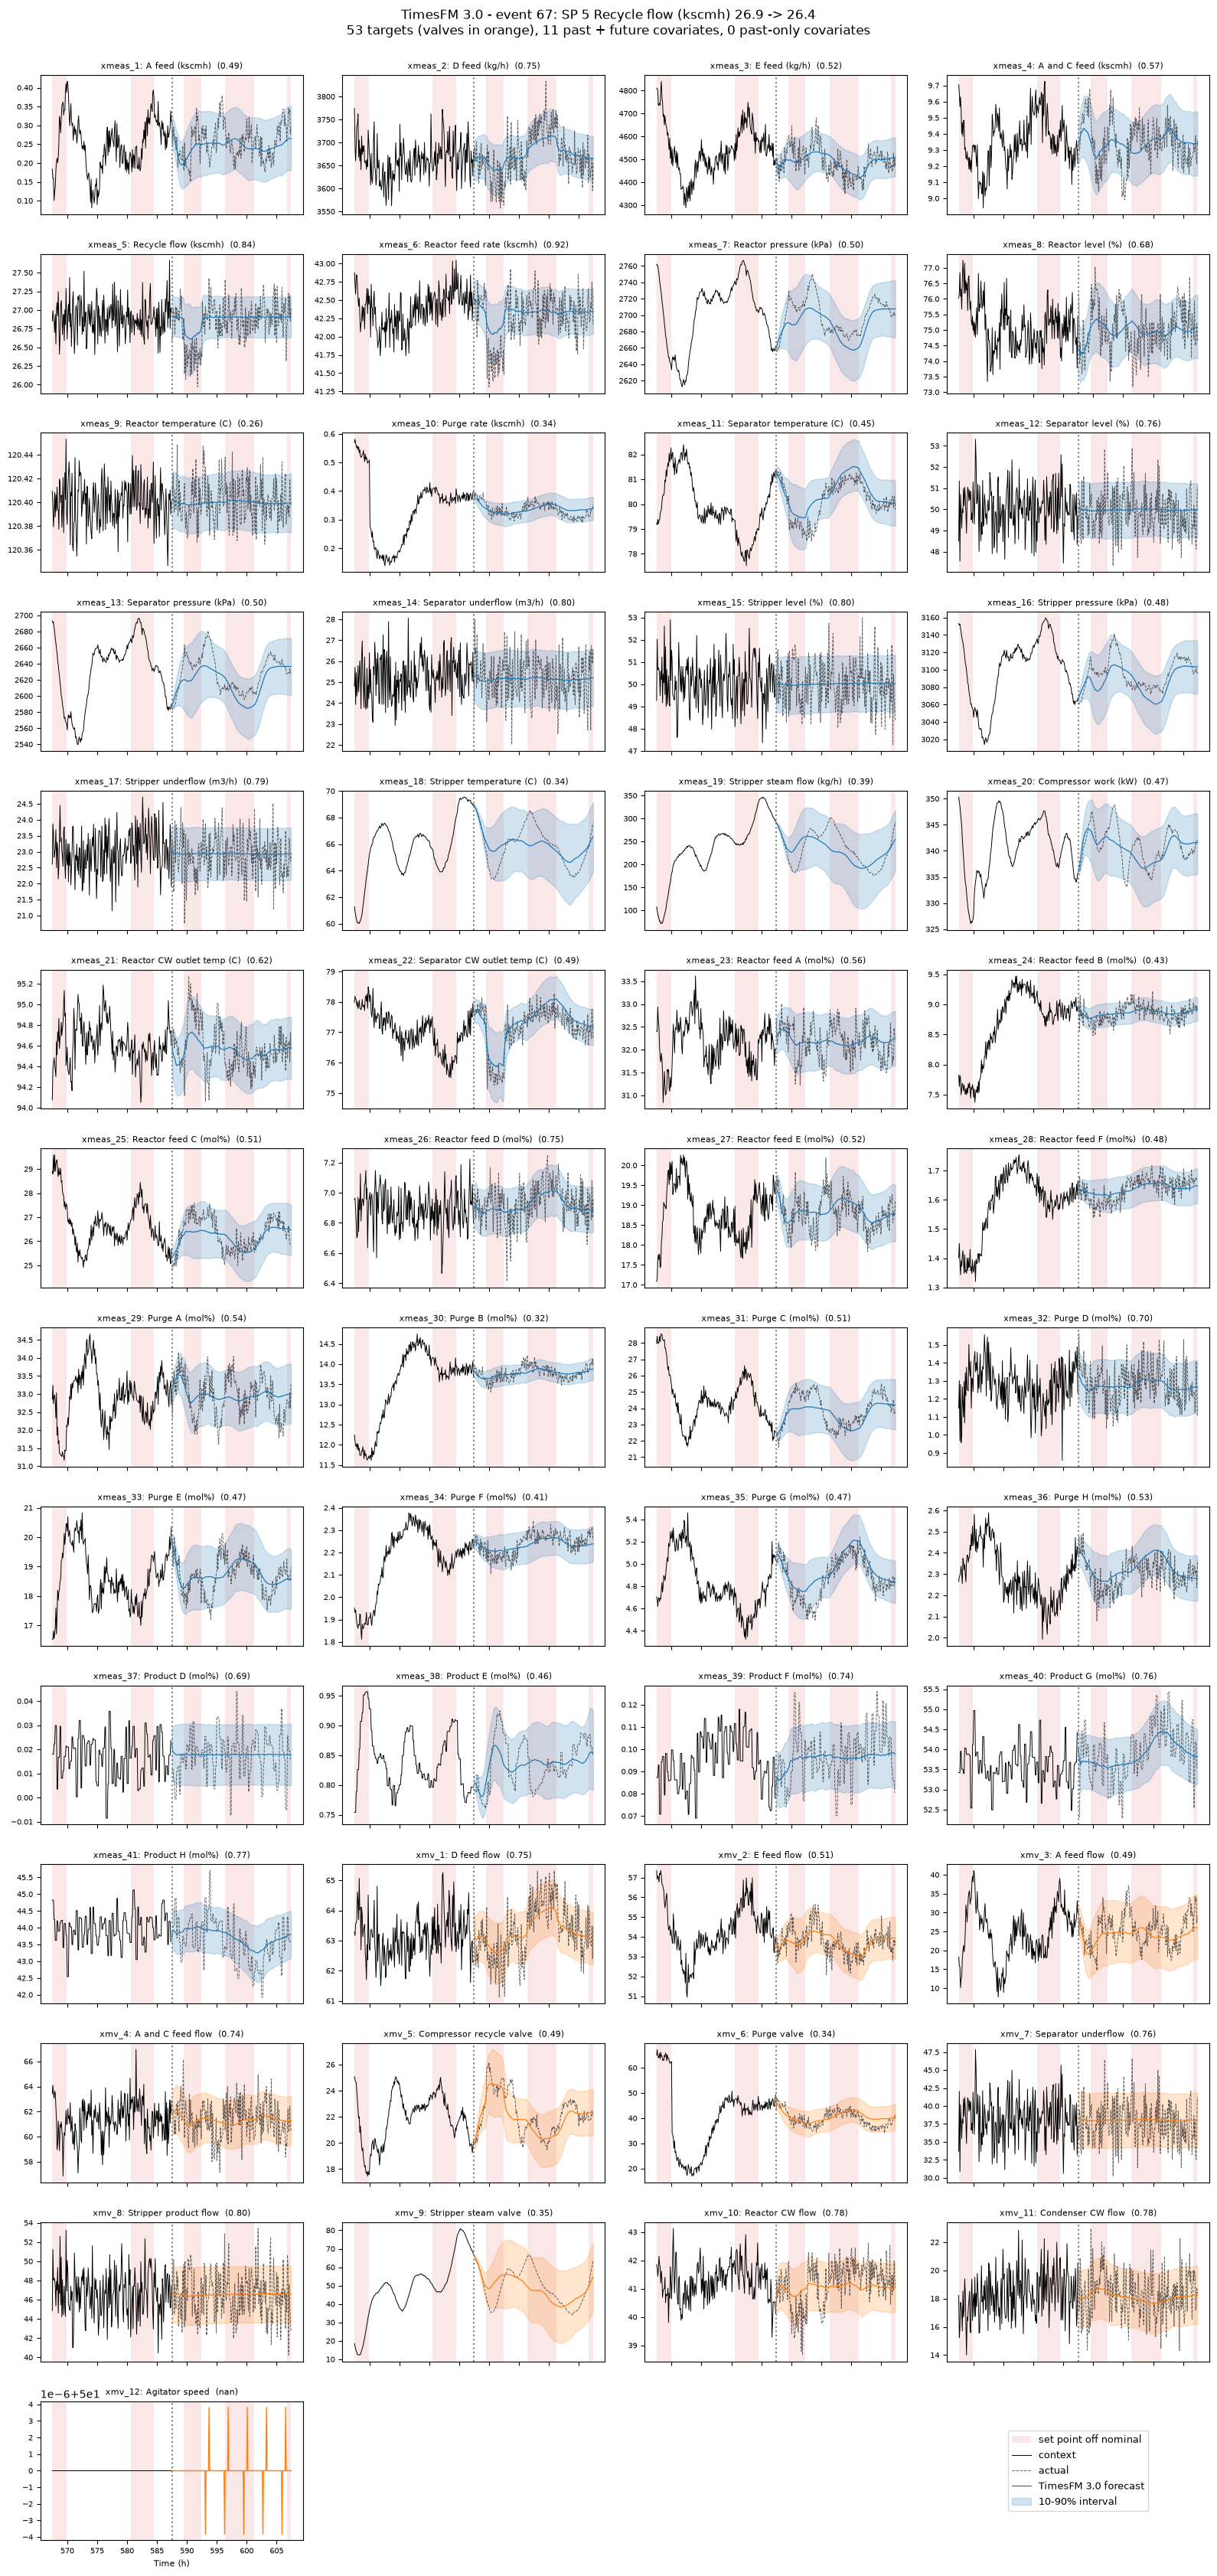

In [7]:
# Plot every target
lead = context_df.iloc[-PLOT_LEAD_IN:]
shown = pd.concat([lead, truth_df])

n_rows = -(-(len(TARGET_COLUMNS) + 1) // 4)
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 2.4 * n_rows), sharex=True)
for ax, col in zip(axes.ravel(), TARGET_COLUMNS):
    sub = pred_df[pred_df["target_name"] == col]
    color = "tab:orange" if col.startswith("xmv") else "tab:blue"
    ax.fill_between(shown["time_h"], 0, 1, where=shown["sp_change"] != 0, color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="set point off nominal")
    ax.plot(lead["time_h"], lead[col], color="black", lw=0.7, label="context")
    ax.plot(truth_df["time_h"], truth_df[col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    ax.plot(sub["time_h"], sub["predictions"], color=color, lw=0.9, label=f"{MODEL_LABEL} forecast")
    ax.fill_between(sub["time_h"], sub["0.1"], sub["0.9"], color=color, alpha=0.2, label="10-90% interval")
    ax.axvline(truth_df["time_h"].iloc[0], color="gray", ls=":")
    ax.set_title(f"{col}: {LABELS[col]}  ({accuracy.loc[col, 'scaled MAE (all)']:.2f})", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(TARGET_COLUMNS):]:
    ax.axis("off")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles, labels, loc="center", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)", fontsize=8)
fig.suptitle(f"{MODEL_LABEL} - event {EVENT_INDEX}: SP {event_sp} {LABELS[f'sp_{event_sp}']} "
             f"{nominal[event_sp]:.4g} -> {event_value:.4g}\n"
             f"{len(TARGET_COLUMNS)} targets (valves in orange), {len(FUTURE_COV)} past + future covariates, "
             f"{len(PAST_ONLY_COV)} past-only covariates", y=1.0)
fig.tight_layout()

In [8]:
# Save results
import os

RESULTS_FILE = "Results/setpointforecast_timesfm3.h5"
ACCURACY_COLUMNS = ["MAE", "scaled MAE (nominal)", "scaled MAE (off nominal)", "scaled MAE (all)",
                    "baseline (nominal)", "baseline (off nominal)", "baseline (all)"]

os.makedirs("Results", exist_ok=True)
with h5py.File(RESULTS_FILE, "w") as f:
    f.attrs["model"] = MODEL_LABEL
    f.attrs["settings"] = json.dumps({
        "data_file": DATA_FILE,
        "event_index": EVENT_INDEX,
        "split": int(SPLIT),
        "horizon": int(HORIZON),
        "future_covariates": FUTURE_COV,
        "past_only_covariates": PAST_ONLY_COV,
    })

    # Accuracy table
    f.create_dataset("variable", data=list(accuracy.index))
    f.create_dataset("description", data=list(accuracy["description"]))
    for name in ACCURACY_COLUMNS:
        f.create_dataset(name, data=accuracy[name].to_numpy())

    # Forecasts, actual values and the end of the context
    f.create_dataset("time_h", data=truth_df["time_h"].to_numpy())
    f.create_dataset("off_nominal", data=truth_df["sp_change"].to_numpy() != 0)
    f.create_dataset("context_time_h", data=lead["time_h"].to_numpy())
    for col in TARGET_COLUMNS:
        sub = pred_df[pred_df["target_name"] == col]
        f.create_dataset(f"forecast/{col}", data=sub["predictions"].to_numpy())
        f.create_dataset(f"lower/{col}", data=sub["0.1"].to_numpy())
        f.create_dataset(f"upper/{col}", data=sub["0.9"].to_numpy())
        f.create_dataset(f"actual/{col}", data=truth_df[col].to_numpy())
        f.create_dataset(f"context/{col}", data=lead[col].to_numpy())
print(f"Saved {MODEL_LABEL} results to {RESULTS_FILE}")


Saved TimesFM 3.0 results to Results/setpointforecast_timesfm3.h5


Saved Figures/setpointforecast_timesfm3_article.pdf and .png


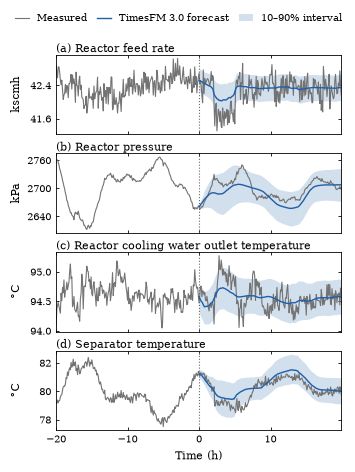

In [9]:
# Article figure: four selected measurements
import os
import re
from matplotlib.ticker import MaxNLocator

ARTICLE_COLUMNS = ["xmeas_6", "xmeas_7", "xmeas_21", "xmeas_11"]
FIGURE_DIR = "Figures"
FORECAST_COLOR = "#1f5fa8"
ARTICLE_STYLE = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
}


def split_label(label):
    name, unit = re.fullmatch(r"(.*?)\s*\((.*)\)", label).groups()
    name = re.sub(r" temp$", " temperature", name.replace("CW", "cooling water"))
    return name, {"C": "°C", "m3/h": "m³/h"}.get(unit, unit)


t0 = truth_df["time_h"].iloc[0]   # forecast start becomes time 0
with plt.rc_context(ARTICLE_STYLE):
    fig, axes = plt.subplots(len(ARTICLE_COLUMNS), 1, figsize=(3.5, 1.1 * len(ARTICLE_COLUMNS)), sharex=True)
    for letter, ax, col in zip("abcdefgh", axes, ARTICLE_COLUMNS):
        sub = pred_df[pred_df["target_name"] == col]
        name, unit = split_label(LABELS[col])
        ax.plot(shown["time_h"] - t0, shown[col], color="0.45", lw=0.8, label="Measured")
        ax.plot(sub["time_h"] - t0, sub["predictions"], color=FORECAST_COLOR, lw=1.0, zorder=3,
                label=f"{MODEL_LABEL} forecast")
        ax.fill_between(sub["time_h"] - t0, sub["0.1"], sub["0.9"], color=FORECAST_COLOR, alpha=0.2, lw=0,
                        label="10–90% interval")
        ax.axvline(0, color="0.4", ls=":", lw=0.8)
        ax.set_title(f"({letter}) {name}", loc="left", pad=2)
        ax.set_ylabel(unit)
        ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.ticklabel_format(axis="y", useOffset=False)
        ax.margins(x=0)
    axes[-1].set_xlabel("Time (h)")
    fig.align_ylabels(axes)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.tight_layout(h_pad=0.3)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,
               handlelength=1.5, columnspacing=1.0)

    os.makedirs(FIGURE_DIR, exist_ok=True)
    stem = os.path.splitext(os.path.basename(RESULTS_FILE))[0]
    for ext in ["pdf", "png"]:
        fig.savefig(f"{FIGURE_DIR}/{stem}_article.{ext}", dpi=600, bbox_inches="tight")
print(f"Saved {FIGURE_DIR}/{stem}_article.pdf and .png")